In [104]:
# download the names.txt file from github
!wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

--2026-09-28 03:56:38--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt.4’

names.txt.4         100%[===================>] 222.80K  --.-KB/s    in 0.005s  

2026-09-28 03:56:38 (42.7 MB/s) - ‘names.txt.4’ saved [228145/228145]



In [105]:
# paper refernce used: https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf

In [106]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [107]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [108]:
len(words)

32033

In [109]:
# building the vocabulary of charactes and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s,i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [110]:
# build the dataset

block_size = 3 # context length: How many characters we use to predict the next char
X, Y = [], []
for w in words:
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '---->', ch)
    context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)


In [111]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [112]:
# build the dataset
def build_dataset(words):
  block_size = 3 # context length: How many characters we use to predict the next char
  X, Y = [], []
  for w in words:
    context = [0] * block_size

    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '---->', ch)
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [113]:
# building the embeddings for our chars.
# we have 27 chars and each char should have their own embeddings.
# For starters, we are going to consider a 2 dimension space for the embeddings.
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
C

tensor([[ 1.5674, -0.2373],
        [-0.0274, -1.1008],
        [ 0.2859, -0.0296],
        [-1.5471,  0.6049],
        [ 0.0791,  0.9046],
        [-0.4713,  0.7868],
        [-0.3284, -0.4330],
        [ 1.3729,  2.9334],
        [ 1.5618, -1.6261],
        [ 0.6772, -0.8404],
        [ 0.9849, -0.1484],
        [-1.4795,  0.4483],
        [-0.0707,  2.4968],
        [ 2.4448, -0.6701],
        [-1.2199,  0.3031],
        [-1.0725,  0.7276],
        [ 0.0511,  1.3095],
        [-0.8022, -0.8504],
        [-1.8068,  1.2523],
        [ 0.1476, -1.0006],
        [-0.5030, -1.0660],
        [ 0.8480,  2.0275],
        [-0.1158, -1.2078],
        [-1.0406, -1.5367],
        [-0.5132,  0.2961],
        [-1.4904, -0.2838],
        [ 0.2569,  0.2130]])

In [114]:
F.one_hot(torch.tensor(5), num_classes = 27).float()

tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [115]:
# We are not going to use this ine_hot apporach as it just masks other indexes and shows that particular row.
# We can directly access the rows like in next cell.
F.one_hot(torch.tensor(5), num_classes = 27).float() @ C

tensor([-0.4713,  0.7868])

In [116]:
# our Actual embedding
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [117]:
C[X][0].shape

torch.Size([3, 2])

In [118]:
w1 = torch.randn((6,100), generator=g) # (The shape is (number of inputs, number of neurons in that laye))
b1 = torch.randn(100, generator=g)

In [119]:
# Now the problem is shape is emb is not appropriate to multiply with w for the emb @ w operation.
# So, we use torch.unbind(emb, 1) which takes all the 32 example's 1st index content and ubinds them. so, basically gives tuple of 3 tensors each tensor
# of shape (32,2).
# we concat all thre tuples now along the index 1, so finally we get (32,6)

torch.cat(torch.unbind(emb, 1), 1)


tensor([[ 1.5674, -0.2373,  1.5674, -0.2373,  1.5674, -0.2373],
        [ 1.5674, -0.2373,  1.5674, -0.2373, -0.4713,  0.7868],
        [ 1.5674, -0.2373, -0.4713,  0.7868,  2.4448, -0.6701],
        ...,
        [ 0.2569,  0.2130,  0.2569,  0.2130, -1.4904, -0.2838],
        [ 0.2569,  0.2130, -1.4904, -0.2838,  0.2569,  0.2130],
        [-1.4904, -0.2838,  0.2569,  0.2130, -0.5132,  0.2961]])

In [120]:
# but we have an better and effecient apporach of doing the same which is using .view((32,6)).
# Need to understand something called as pytorch internals to understand why this is effecient.
emb.view(-1,6)

tensor([[ 1.5674, -0.2373,  1.5674, -0.2373,  1.5674, -0.2373],
        [ 1.5674, -0.2373,  1.5674, -0.2373, -0.4713,  0.7868],
        [ 1.5674, -0.2373, -0.4713,  0.7868,  2.4448, -0.6701],
        ...,
        [ 0.2569,  0.2130,  0.2569,  0.2130, -1.4904, -0.2838],
        [ 0.2569,  0.2130, -1.4904, -0.2838,  0.2569,  0.2130],
        [-1.4904, -0.2838,  0.2569,  0.2130, -0.5132,  0.2961]])

In [121]:
# Here -1 in the view "figure out this dimension automatically, based on the total number of elements and the other dimension(s) I specified."
h = torch.tanh(emb.view(-1,6)@w1 + b1)
h.shape

torch.Size([228146, 100])

In [122]:
# now mocing on to layer 2 which is the output layer.
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

In [123]:
logits = h @ w2 + b2
logits.shape

torch.Size([228146, 27])

In [124]:
# Now apply softmax activations
counts = logits.exp()
print(counts.shape)
prob = counts/counts.sum(1, keepdim=True)

torch.Size([228146, 27])


In [125]:
prob.shape

torch.Size([228146, 27])

In [126]:
# Now Calculating the loss
loss = -prob[torch.arange(228146), Y].log().mean()
loss

tensor(19.5052)

In [127]:
# =================EVERYTHING SO FAR TOGETHER=================

In [128]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [160]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,10), generator=g)
w1 = torch.randn((30,200), generator=g)
b1 = torch.randn(200, generator=g)
w2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]

In [161]:
sum(p.nelement() for p in parameters) # number of parameters

11897

In [162]:
for p in parameters:
  p.requires_grad = True

In [163]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [165]:
lri = []
lossi = []
stepi = []

In [188]:
for i in range(50000):

  # mini-batch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))

  # Forward Pass
  emb = C[Xtr[ix]] # (32,3,2)
  h = torch.tanh(emb.view(-1,30)@w1 + b1)
  logits = h @ w2 + b2
  # counts = logits.exp()
  # prob = counts/counts.sum(1, keepdim=True)
  # loss = -prob[torch.arange(32), Y].log().mean()
  loss = F.cross_entropy(logits, Ytr[ix])  # Much more effecient


  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  #update
  # lr = lrs[i]
  lr = 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # # track stats
  # lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

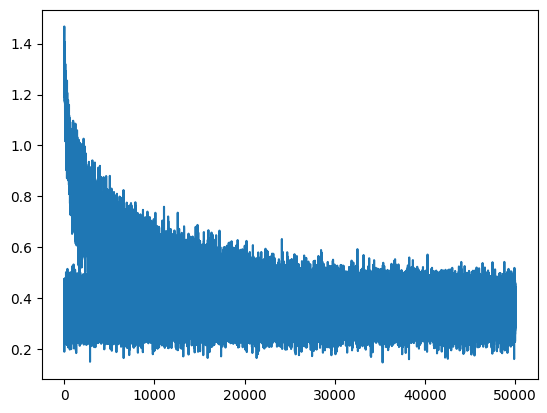

In [189]:

plt.plot(stepi, lossi)

In [190]:
emb = C[Xtr] # (32,3,2)
h = torch.tanh(emb.view(-1,30)@w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ytr)

loss

tensor(2.2410, grad_fn=<NllLossBackward0>)

In [191]:
emb = C[Xdev] # (32,3,2)
h = torch.tanh(emb.view(-1,30)@w1 + b1)
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ydev)

loss

tensor(2.2541, grad_fn=<NllLossBackward0>)

In [192]:
# training split - train, dev/validation, test split
# 80%, 10%, 10%

In [193]:
# Checking our Model output
g = torch.Generator().manual_seed(2147483647)

for i in range(20):
  out = []
  context = [0,0,0]

  while True:
    emb = C[torch.tensor([context])]        # shape (1, 3, 2)
    h = torch.tanh(emb.view(1, -1) @ w1 + b1)
    logits = h @ w2 + b2
    counts = logits.exp()
    p = counts / counts.sum(1, keepdim=True)
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    context = context[1:] + [ix]            # slide the window: drop oldest, add new
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

dex.
mariah.
makilah.
tah.
mellissana.
malka.
kaman.
arra.
zylueltahriiotai.
moriellahu.
keiteda.
kaley.
maside.
eniavirry.
folspefini.
gavtahlas.
dashr.
breenley.
alaira.
jana.
